## smoother.py - bayesian smoothing of a probability raster

This notebook applies `smoother.smooth`, with its default Bayesian method (`method="bayes"`), to a real classification output produced using the [`sits`](https://github.com/e-sensing/sits) R package. In this case, the GeoTIFF contains one band per land-use class (`1 = Cerrado`, `2 = Forest`, `3 = Pasture`, `4 = Soy corn`)

It runs the same data through both entry points of the package:

- the [numpy](https://numpy.org/) backend, loading the raster with [`rasterio`](https://rasterio.readthedocs.io);
- the [xarray](https://docs.xarray.dev/en/stable/index.html) backend, loading it with [`rioxarray`](https://corteva.github.io/rioxarray) so the CRS and coordinates ride along.

Install the example dependencies first:

```bash
pip install "smoother-py[examples]"   # or: uv sync --extra examples
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
import rioxarray  # noqa: F401  (registers the .rio accessor on xarray objects)
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

import smoother

# Define classification file
DATA = Path("data") / "TERRA_MODIS_012010_2013-09-14_2014-08-29_probs_v1.tif"

# Class palette, in band order (taken from data/style.qml).
CLASSES = [
    ("Cerrado", "#a2d43f"),
    ("Forest", "#1E8449"),
    ("Pasture", "#FAD12D"),
    ("Soy_Corn", "#D68910"),
]

## A small plotting helper

Both workflows produce a `(class, y, x)` probability array. The most likely class at each pixel is the `argmax` over the class axis. We draw it with the palette above and put the `original` and `smoothed` maps side by side.

In [2]:
def plot_class_maps(before, after, titles=("Original", "Bayesian smoothed")):
    """Plot the most likely class before and after smoothing, side by side."""
    cmap = ListedColormap([color for _, color in CLASSES])
    cmap.set_bad("white")  # nodata (pixels with no class probability)

    # define figure
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)

    # plot figures
    for ax, probs, title in zip(axes, (before, after), titles):
        # get classes
        classes = np.ma.masked_where(probs.sum(axis=0) == 0, np.argmax(probs, axis=0))

        # show image
        ax.imshow(
            classes, cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"
        )

        # set title and disable axis
        ax.set_title(title)
        ax.set_axis_off()

    # define handles
    handles = [Patch(facecolor=color, label=label) for label, color in CLASSES]

    # apply in the figure
    fig.legend(handles=handles, loc="outside lower center", ncol=len(CLASSES))

    # return figure
    return fig

## 1. numpy workflow

`rasterio` reads a multi-band raster as a `(band, y, x)` array, which is exactly the `(class, y, x)` layout `smoother.smooth` expects.

The bands here are integers scaled to `0-10000`, so we first turn them into probabilities and nudge them away from exactly `0`/`1`, where the logit transform used internally by the bayes method is undefined.

In [3]:
# load probs data
with rasterio.open(DATA) as src:
    probs = src.read().astype("float64")  # (class, y, x), scaled 0-10000

# scale the integers to probabilities and keep them inside (0, 1)
probs /= probs.sum(axis=0, keepdims=True)
probs = probs.clip(1e-4, 1.0)

# smooth!
smoothed = smoother.smooth(probs)

# the output keeps the input shape and stays within valid probability bounds
assert smoothed.shape == probs.shape
assert (smoothed >= 0).all() and (smoothed <= 1).all()

probs.shape

(4, 147, 255)

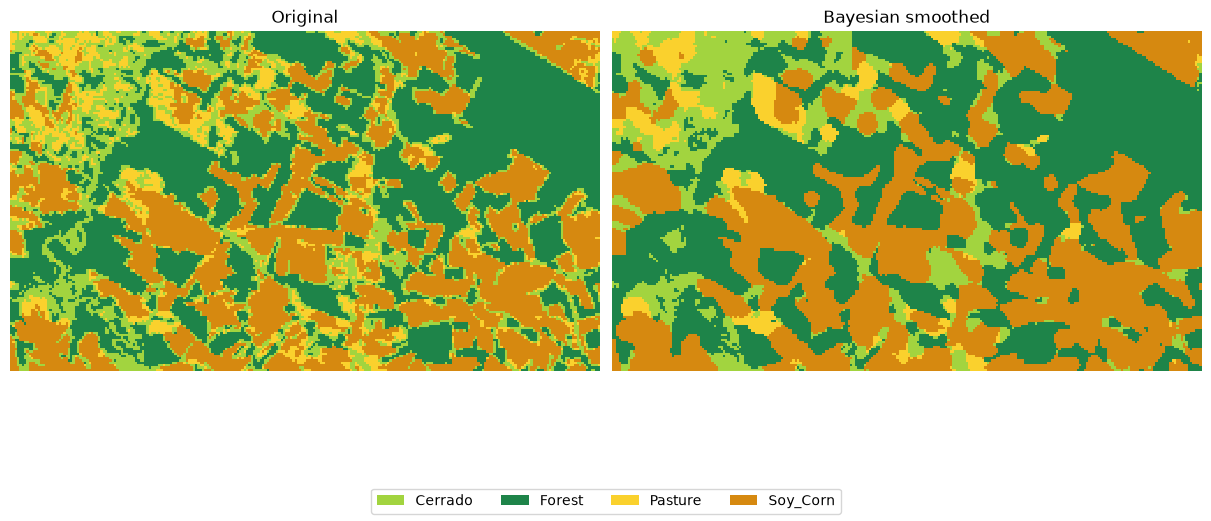

In [4]:
plot_class_maps(probs, smoothed);

Smoothing removes the isolated "salt-and-pepper" misclassifications while preserving the larger regions. The result depends on three parameters:

- `window_size` - size of the neighbourhood, an odd integer >= 3 (default `9`);
- `smoothness` - estimated variance of the class logits, one number or one per class (default `20`);
- `neigh_fraction` - fraction of high-probability neighbours used (default `0.5`).

A larger `smoothness` produces a stronger effect, e.g. `smoothness=50`.

## 2. xarray workflow

With `rioxarray` the raster becomes a `DataArray` whose `band`, `y` and `x`
dimensions are recognised automatically, so the call is identical. Dimensions,
coordinates and the CRS are carried through the smoothing untouched.

In [5]:
da = rioxarray.open_rasterio(DATA).astype("float64")  # dims: (band, y, x)

# same preprocessing as above, expressed with xarray operations
da = (da / da.sum("band")).clip(1e-4, 1.0)

smoothed_da = smoother.smooth(da)

# dims, coordinates and the CRS survive the smoothing
assert smoothed_da.dims == da.dims

# show details
print("dims:", smoothed_da.dims)
print("crs: ", smoothed_da.rio.crs)

# complete xarray object
smoothed_da

dims: ('band', 'y', 'x')
crs:  PROJCS["unnamed",GEOGCS["Unknown datum based upon the custom spheroid",DATUM["Not_specified_based_on_custom_spheroid",SPHEROID["Custom spheroid",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]


<xarray.DataArray (band: 4, y: 147, x: 255)> Size: 1MB
array([[[5.22942047e-01, 5.12594371e-01, 5.27925820e-01, ...,
         6.55950818e-02, 7.18636273e-02, 7.28751655e-02],
        [5.58295413e-01, 5.48103337e-01, 5.94549977e-01, ...,
         5.96140271e-02, 9.01320958e-02, 8.50178509e-02],
        [5.82191997e-01, 5.71200098e-01, 6.11677888e-01, ...,
         1.50208405e-01, 1.42205662e-01, 1.35867919e-01],
        ...,
        [1.66571629e-01, 2.29687409e-01, 3.30995991e-01, ...,
         4.07074179e-01, 4.03687695e-01, 3.39205710e-01],
        [1.55129446e-01, 2.00739852e-01, 3.27451797e-01, ...,
         4.20025927e-01, 3.79888553e-01, 3.93276437e-01],
        [1.41392470e-01, 2.07024177e-01, 3.55053709e-01, ...,
         5.28173539e-01, 4.11103583e-01, 4.20946500e-01]],

       [[4.68836367e-03, 6.43914256e-03, 2.83402608e-04, ...,
         1.37335309e-04, 1.18530421e-04, 9.99900010e-05],
        [4.93637497e-04, 6.55742293e-03, 3.87711183e-04, ...,
         1.56596970e-04, 1.37333039e-04, 1.18530049e-04],
        [5.31758798e-04, 6.12929766e-04, 5.23530058e-04, ...,
         1.99322068e-04, 1.78475836e-04, 1.80327880e-04],
...
         9.52009288e-02, 8.80447295e-02, 9.63153795e-02],
        [2.20491491e-01, 2.32102310e-01, 2.30833379e-01, ...,
         6.58855660e-02, 6.47138421e-02, 3.81372831e-02],
        [2.16500443e-01, 2.31688137e-01, 2.31190292e-01, ...,
         8.85637851e-02, 5.08917233e-02, 5.84431973e-02]],

       [[3.05304239e-02, 3.17793632e-02, 2.85297795e-02, ...,
         9.66496830e-01, 9.52380173e-01, 9.53477824e-01],
        [3.00400009e-02, 4.03357737e-02, 3.90854351e-02, ...,
         9.97130725e-01, 9.77031136e-01, 9.54404215e-01],
        [1.73740315e-02, 2.99784814e-02, 2.86293181e-02, ...,
         9.45769925e-01, 9.52672557e-01, 9.08572891e-01],
        ...,
        [8.01895211e-01, 8.01412562e-01, 7.80641969e-01, ...,
         3.70670719e-01, 5.67835629e-01, 7.91346281e-01],
        [8.17135846e-01, 8.17135846e-01, 7.94976826e-01, ...,
         7.95246263e-03, 1.06167914e-02, 1.62989729e-02],
        [8.24086028e-01, 8.23973147e-01, 8.03889495e-01, ...,
         5.24225989e-02, 1.09522665e-02, 1.51540540e-02]]],
      shape=(4, 147, 255))
Coordinates:
  * band         (band) int64 32B 1 2 3 4
  * y            (y) float64 1kB -1.278e+06 -1.279e+06 ... -1.312e+06 -1.312e+06
  * x            (x) float64 2kB -6.074e+06 -6.073e+06 ... -6.015e+06 -6.015e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     65535
    scale_factor:   1.0
    add_offset:     0.0

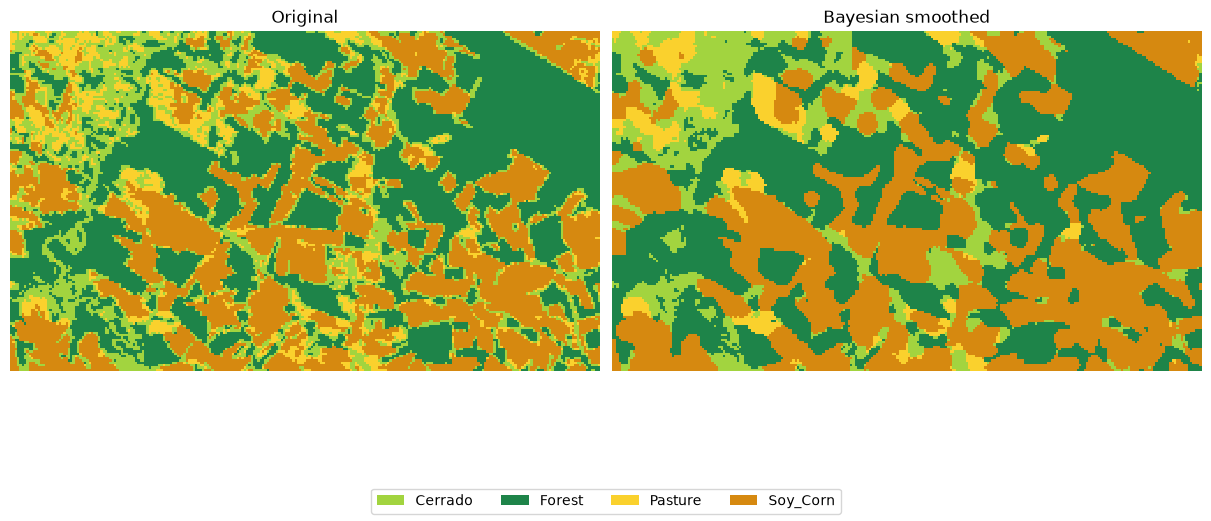

In [6]:
plot_class_maps(da.values, smoothed_da.values);

An extra dimension such as `time` would be handled automatically: each layer is smoothed independently, and dask-backed arrays are processed in parallel.

See the [project README](../README.md) and the [sits book chapter](https://e-sensing.github.io/sitsbook/cl_smoothing.html) for the method's background.